# Downtime and production-loss drivers

**Goal:** minimise downtime and production losses on Strathcona's producing oil wells.

1. **3.1** Which factors contribute most to `lost_oil_m3` and `hours_down`?
2. **3.2** Which failure types/details sit behind those factors?
3. **3.3** How much does each problem cost: repair cost (`field_est_total`) vs. lost revenue (`lost_oil_m3` x oil price)?
4. **3.4** Evidence for an implementation plan, with an estimated profit increase (scenario ranges).

**How to run:** put the three competition parquet files in the repository root, then run all cells top to bottom
(about 15-25 minutes on a laptop; the model-tuning cell is the slowest). Figures and tables are written to `outputs/`.

**Wording:** SHAP values and correlations show *association*, not causation. "Cause" is only used where the
failure records themselves state a cause.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb
from IPython.display import display
from sklearn.metrics import average_precision_score, mean_absolute_error, mean_squared_error, roc_auc_score
from sklearn.model_selection import ParameterSampler, TimeSeriesSplit

import data_utils as du

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

RANDOM_STATE = 42
OUT = du.REPO_ROOT / "outputs"
OUT.mkdir(exist_ok=True)

# ---- Editable assumptions (confirm with the team) ---------------------------------------
# Heavy-oil price in CAD per barrel. PLACEHOLDER values: an approximate range for
# Western Canadian Select (WCS) over 2021-2025, converted to CAD. Replace with the team's
# chosen source and date before presenting.
OIL_PRICE_CAD_PER_BBL = {"low": 55.0, "base": 75.0, "high": 95.0}
BBL_PER_M3 = 6.2898
LINK_WINDOW_DAYS = 3          # failures/jobs within [episode start - 3d, episode end + 3d]
ALERT_LEAD_DAYS = 7           # an alert counts if it fired within 7 days before an episode
INSPECTION_COST_CAD = 1_500   # PLACEHOLDER cost of one well check triggered by an alert
OIL_FLUID_TYPES = ["Heavy Oil", "Oil"]
# Downtime classes the model and plan focus on (see 3.0). Edit to widen the scope.
ANALYSIS_CLASSES = ["Equipment failure"]


def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")


def save_table(df, name):
    df.to_csv(OUT / f"{name}.csv")

## Downtime-code classification (editable)

The daily file mixes **two coding systems**: descriptive codes (`Downhole Equipment / Rods`) and legacy short codes
(`RODSPART / DH - Rodstring Failure`, `CODE3 / DH - Tubing Failure`, `UNECO10 / UNECO - High OPEX`, ...).
The ordered keyword rules below map every `(downtime_code_2, downtime_code_3)` pair to one **problem** and one
**class**. The first matching rule wins and the text searched is `"code_2 | code_3"` in lower case.
For example, `UNECO - Tubing Failure` is classed as *Economic*, not as a tubing failure: the operator chose not
to repair the well.

In [2]:
DOWNTIME_RULES = [
    # (keywords, problem, class)
    (["uneco", "long term shut", "long-term shut", "ltsi", "high opex", "high watercut", "low inflow"],
     "Uneconomic / long-term shut-in", "Economic"),
    (["rod"], "Rod string failure", "Equipment failure"),
    (["pump"], "Pump failure / problems", "Equipment failure"),
    (["tubing"], "Tubing failure", "Equipment failure"),
    (["torqued"], "Well torqued", "Equipment failure"),
    (["wellhead drive", "stuffing"], "Wellhead drive / stuffing box", "Equipment failure"),
    (["engine/motor"], "Engine / motor down", "Equipment failure"),
    (["electrical", "genset", "elfail"], "Electrical failure", "Equipment failure"),
    (["belt"], "Belt problems", "Equipment failure"),
    (["compressor"], "Compressor problems", "Equipment failure"),
    (["packer", "gas-locking", "loaded", "waxed", "plunger", "gas lift failure", "downhole obstruction",
      "disposal well repairs", "down hole failure", "downhole equipment | unspecified", "service rig on hole"],
     "Other downhole problem", "Equipment failure"),
    (["flowline failure", "flowline maintenance", "flowline hydrate", "hydrate", "obstruction",
      "pipeline/equipment failure"], "Flowline / pipeline problem", "Equipment failure"),
    (["esd", "high pressure/level", "process upset", "process shutdown"],
     "Facility upset / emergency shutdown", "Equipment failure"),
    (["equipment failure", "equipment malfunction"], "Other equipment failure", "Equipment failure"),
    (["limited capacity", "capacity constraint", "high pipeline pressure", "restrictions",
      "water source supply", "lift gas supply", "trucking", "third party"],
     "Facility capacity / supply constraint", "Facility constraint"),
    (["grid", "weather", "planned outage", "scrl", "power"], "Power outage / weather", "External"),
    (["regulatory", "spill", "lease", "road", "non-operated", "non - op", "surface access"],
     "Regulatory / environment / access", "External"),
    (["drill", "frac", "polymer", "eor", "voidage", "offset", "proximity", "completions",
      "stimulation", "optimization"], "Development / drilling / stimulation", "Development"),
    (["turn around", "maintenance", "workover", "construction", "install new", "tie-in", "tie in",
      "artificial lift", "pressure acquisition", "facility downtime"],
     "Planned maintenance / turnaround", "Planned maintenance"),
]


def classify_code(code_2, code_3):
    if pd.isna(code_2) and pd.isna(code_3):
        return "Unknown (no code)", "Unknown"
    text = f"{code_2} | {code_3}".lower()
    for keywords, problem, cls in DOWNTIME_RULES:
        if any(k in text for k in keywords):
            return problem, cls
    return "Unmatched", "Unknown"

## Load and clean the data

Rules from `data_utils.py`. Placeholders and impossible values become NaN and rows are never dropped.
`lost_oil_m3` is NaN on zero-downtime days, so it is filled with 0 there; downtime days with no loss estimate stay NaN.

In [3]:
DAILY_COLS = [
    "uwi", "production_date", "flow_direction", "well_daily_status", "primary_fluid_type",
    "field_operating_area", "facility_name", "on_production_date", "hours_down", "lost_oil_m3",
    "downtime_code_2", "downtime_code_3", "oil_produced_m3", "water_produced_m3", "gas_produced_e3m3",
    "pump_efficiency_pct", "pcp_pump_rpm", "pcp_pump_rod_torque_ftlb", "pcp_pump_electric_current_a",
    "tubing_pressure_kpa", "casing_pressure_kpa", "pcp_pump_volume_throughput_m3d",
    "pcp_pump_displacement_m3d100rpm", "pcp_pump_make", "pcp_pump_model",
]
raw = du.load_daily(DAILY_COLS)
prod = du.producers_only(raw)
del raw
prod = du.convert_types(prod)
prod, cleaning_report = du.clean_daily(prod, return_report=True)
save_table(cleaning_report, "cleaning_report_daily")

oil_mask = prod["primary_fluid_type"].isin(OIL_FLUID_TYPES)
print(f"Oil wells only (Heavy Oil + Oil): kept {oil_mask.sum():,} of {len(prod):,} producer rows "
      f"(gas and water-source producers have no oil to lose)")
prod = prod.loc[oil_mask]

dups = prod.duplicated(["uwi", "production_date"], keep=False)
print(f"Duplicate (uwi, date) rows: {dups.sum():,}; keeping the row with the most hours_down for each pair")
prod = (prod.sort_values(["uwi", "production_date", "hours_down"], ascending=[True, True, False])
            .drop_duplicates(["uwi", "production_date"])
            .reset_index(drop=True))
print(f"Rows: {len(prod):,} | wells: {prod['uwi'].nunique():,} | "
      f"dates: {prod['production_date'].min().date()} to {prod['production_date'].max().date()}")

producers_only: kept 3,778,723 of 5,075,590 rows


  production_date                  -> datetime (0 values could not be parsed)


  on_production_date               -> datetime (0 values could not be parsed)


  pcp_pump_rpm                     -> numeric  (0 values could not be parsed)


lost_oil_m3: filled 2,107,643 zero-downtime days with 0; 24,735 downtime days have no loss estimate (left NaN).
                        column                                rule  values_set_to_nan  non_null_before
           tubing_pressure_kpa placeholder in [999999, -1, -13.79]                  0    2,285,634.000
           casing_pressure_kpa                 placeholder in [-1]                  0    2,489,500.000
           tubing_pressure_kpa                   negative pressure                  3    2,285,634.000
           casing_pressure_kpa                   negative pressure                391    2,489,500.000
           pump_efficiency_pct                  outside [0.0, 1.5]              22000    1,684,781.000
                  pcp_pump_rpm               outside [0.0, 1000.0]               6815    2,341,414.000
               oil_produced_m3                 outside [0.0, None]               3720    3,777,879.000
             water_produced_m3                 outside [0.0, Non

Duplicate (uwi, date) rows: 54; keeping the row with the most hours_down for each pair


Rows: 3,351,538 | wells: 1,990 | dates: 2021-01-01 to 2026-10-26


In [4]:
pairs = (prod.loc[prod["hours_down"] > 0, ["downtime_code_2", "downtime_code_3"]]
             .astype("string").drop_duplicates())
pairs[["problem", "downtime_class"]] = [classify_code(a, b) for a, b in pairs.itertuples(index=False)]
assert (pairs["problem"] != "Unmatched").all(), pairs[pairs["problem"] == "Unmatched"]
code_map = pairs.set_index(["downtime_code_2", "downtime_code_3"])
save_table(code_map.sort_index(), "downtime_code_mapping")

keys = pd.MultiIndex.from_frame(prod[["downtime_code_2", "downtime_code_3"]].astype("string"))
prod["problem"] = code_map["problem"].reindex(keys).to_numpy()
prod["downtime_class"] = code_map["downtime_class"].reindex(keys).to_numpy()
prod.loc[prod["hours_down"] <= 0, ["problem", "downtime_class"]] = "No downtime"
prod["problem"] = prod["problem"].astype("category")
prod["downtime_class"] = prod["downtime_class"].astype("category")
print(f"{len(pairs)} distinct code pairs mapped to {pairs['problem'].nunique()} problems "
      f"and {pairs['downtime_class'].nunique()} classes")

149 distinct code pairs mapped to 20 problems and 7 classes


## 3.0 Controllable vs. non-controllable downtime

,downtime_days,hours_down,lost_oil_m3,share_of_hours,share_of_lost_oil,lost_oil_m3_per_downtime_day
downtime_class,,,,,,
Equipment failure,155275,"3,045,895.750","272,092.770",0.088,0.451,1.752
Economic,1246872,"29,921,805.000","175,577.845",0.860,0.291,0.141
Planned maintenance,20519,"351,467.250","62,869.854",0.010,0.104,3.064
Facility constraint,26471,"610,981.100","38,752.256",0.018,0.064,1.464
Development,17424,"406,158.750","29,118.474",0.012,0.048,1.671
External,26946,"205,494.750","23,976.744",0.006,0.040,0.890
Unknown,15850,"253,558.350",840.578,0.007,0.001,0.053


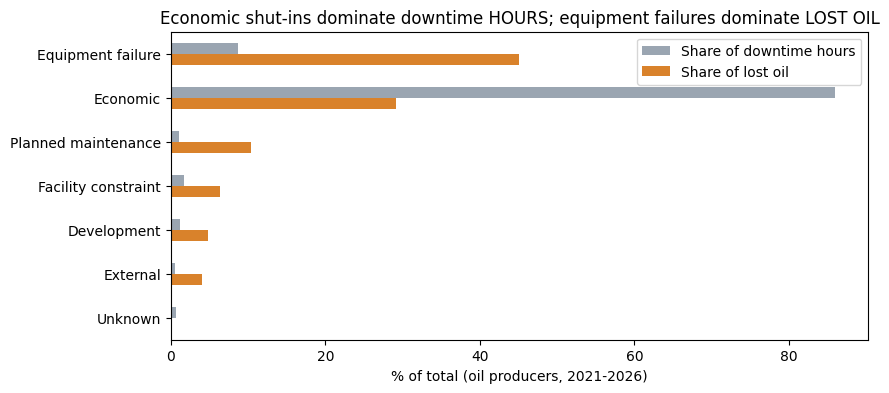

In [5]:
down = prod[prod["hours_down"] > 0]
class_share = (down.groupby("downtime_class", observed=True)
                   .agg(downtime_days=("hours_down", "size"), hours_down=("hours_down", "sum"),
                        lost_oil_m3=("lost_oil_m3", "sum")))
class_share["share_of_hours"] = class_share["hours_down"] / class_share["hours_down"].sum()
class_share["share_of_lost_oil"] = class_share["lost_oil_m3"] / class_share["lost_oil_m3"].sum()
class_share["lost_oil_m3_per_downtime_day"] = class_share["lost_oil_m3"] / class_share["downtime_days"]
class_share = class_share.sort_values("lost_oil_m3", ascending=False)
display(class_share)
save_table(class_share, "3_0_downtime_class_shares")

fig, ax = plt.subplots(figsize=(9, 4))
class_share[["share_of_hours", "share_of_lost_oil"]].mul(100).plot.barh(ax=ax, color=["#9aa5b1", "#d9822b"])
ax.invert_yaxis()
ax.set(xlabel="% of total (oil producers, 2021-2026)", ylabel="",
       title="Economic shut-ins dominate downtime HOURS; equipment failures dominate LOST OIL")
ax.legend(["Share of downtime hours", "Share of lost oil"])
save_fig(fig, "3_0_downtime_class_shares")
plt.show()

**Reading:** long-term *uneconomic* shut-ins account for most downtime hours. They are business decisions on
low-rate wells, so they lose relatively little oil per day. **Equipment failures** are a small share of the hours
but the largest share of lost oil, because they hit wells that were producing. They are also controllable, so the
rest of the analysis focuses on them (`ANALYSIS_CLASSES`). Economic downtime is reported only as context.

## 3.1 Which factors contribute most (Goal step 1)
### A. Pareto view (equipment-failure downtime)

Equipment-failure downtime days: 155,275 | hours: 3,045,896 | lost oil: 272,093 m3


,hours_down,lost_oil_m3,wells,share,cumulative_share
problem,,,,,
Rod string failure,"1,203,202.350","120,402.420",1012,0.443,0.443
Pump failure / problems,"639,357.750","38,470.267",910,0.141,0.584
Tubing failure,"438,294.250","32,445.534",552,0.119,0.703
Well torqued,"193,635.250","18,599.356",443,0.068,0.771
Facility upset / emergency shutdown,"70,085.000","12,225.787",1159,0.045,0.816
Engine / motor down,"107,077.000","11,940.261",654,0.044,0.860
Other downhole problem,"128,377.500","10,165.565",371,0.037,0.898
Flowline / pipeline problem,"76,676.000","8,117.095",621,0.030,0.928
Wellhead drive / stuffing box,"80,857.750","7,835.919",725,0.029,0.956


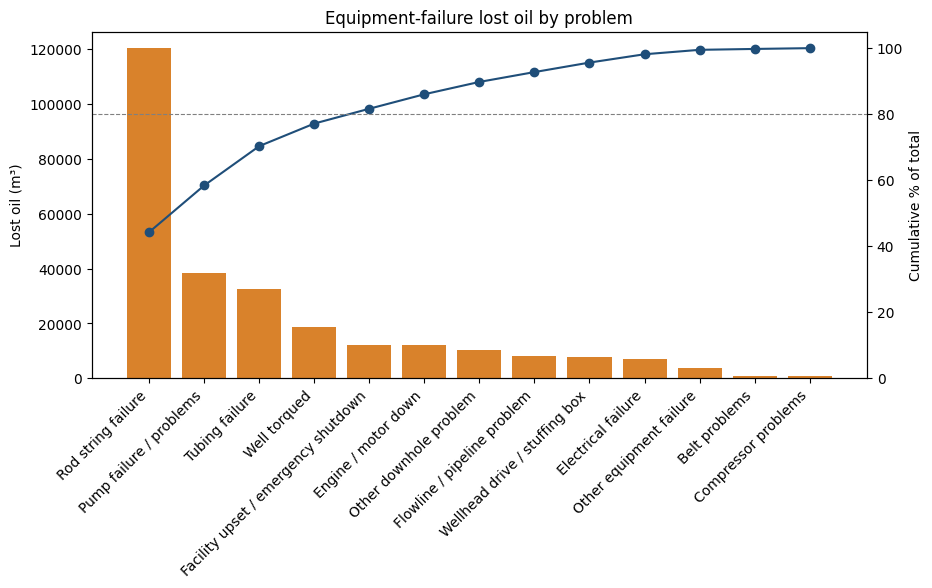

In [6]:
eq = down[down["downtime_class"].isin(ANALYSIS_CLASSES)].copy()
print(f"Equipment-failure downtime days: {len(eq):,} | hours: {eq['hours_down'].sum():,.0f} | "
      f"lost oil: {eq['lost_oil_m3'].sum():,.0f} m3")


def pareto(df, by, value="lost_oil_m3", top=15):
    t = (df.groupby(by, observed=True)
           .agg(hours_down=("hours_down", "sum"), lost_oil_m3=("lost_oil_m3", "sum"),
                wells=("uwi", "nunique"))
           .sort_values(value, ascending=False))
    t["share"] = t[value] / t[value].sum()
    t["cumulative_share"] = t["share"].cumsum()
    return t


def plot_pareto(t, title, name, value="lost_oil_m3", top=15, xlabel=None):
    t = t.head(top)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    labels = [str(i) if not isinstance(i, tuple) else " / ".join(map(str, i)) for i in t.index]
    ax.bar(range(len(t)), t[value], color="#d9822b")
    ax.set_xticks(range(len(t)), labels, rotation=45, ha="right")
    ax.set_ylabel("Lost oil (m³)" if value == "lost_oil_m3" else "Downtime hours")
    ax2 = ax.twinx()
    ax2.plot(range(len(t)), t["cumulative_share"] * 100, color="#1f4e79", marker="o")
    ax2.axhline(80, color="grey", ls="--", lw=0.8)
    ax2.set_ylim(0, 105)
    ax2.set_ylabel("Cumulative % of total")
    ax.set_title(title)
    if xlabel:
        ax.set_xlabel(xlabel)
    save_fig(fig, name)
    plt.show()


pareto_problem = pareto(eq, "problem")
display(pareto_problem)
save_table(pareto_problem, "3_1_pareto_problem")
plot_pareto(pareto_problem, "Equipment-failure lost oil by problem", "3_1_pareto_problem")

,hours_down,lost_oil_m3,wells,share,cumulative_share
field_operating_area,,,,,
Cactus Lake,"890,901.750","81,781.990",503,0.301,0.301
Winter,"642,418.750","66,180.315",207,0.243,0.544
Druid Main,"294,900.000","35,066.994",158,0.129,0.673
Bodo East,"139,668.000","23,140.428",87,0.085,0.758
Cosine,"86,239.000","20,534.071",71,0.075,0.833
Court,"254,715.000","15,768.018",101,0.058,0.891
Druid North East,"141,643.000","13,193.281",45,0.048,0.940
Bellis,"61,558.500","4,373.955",25,0.016,0.956
Bodo South,"158,765.500","3,490.655",19,0.013,0.969


,hours_down,lost_oil_m3,wells,share,cumulative_share
pump,,,,,
no PCP record,"239,957.250","13,452.768",116,0.049,0.049
Weatherford 160-800,"114,902.000","13,371.935",70,0.049,0.099
MANTL 85-1400,"93,727.750","11,055.447",100,0.041,0.139
PCM 80-1350,"100,083.000","9,568.215",119,0.035,0.174
LSI 105-1200,"45,204.000","6,880.947",52,0.025,0.200
BMW Pump 160-800,"71,866.000","6,570.401",44,0.024,0.224
PCM 100-1200,"44,685.500","6,497.946",63,0.024,0.248
LSI 120-1200,"32,954.500","5,481.650",34,0.020,0.268
LSI 43-1500,"13,955.500","5,055.599",14,0.019,0.286


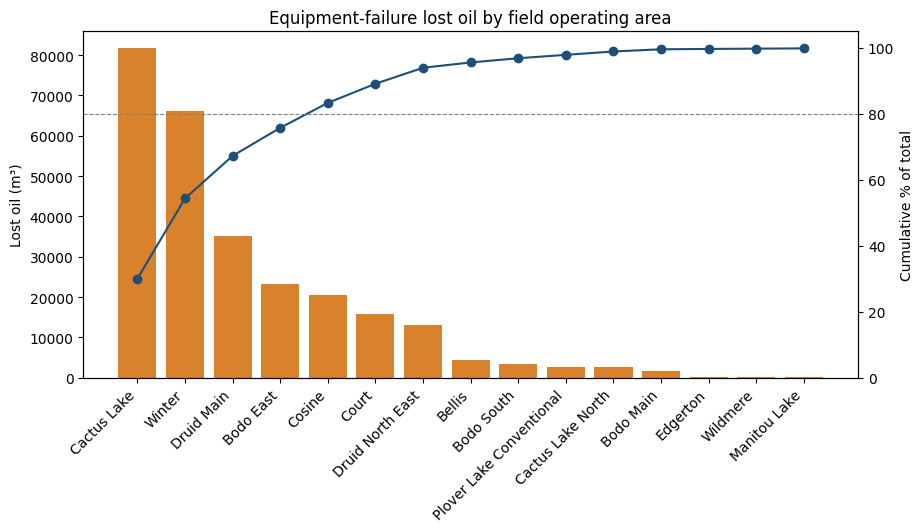

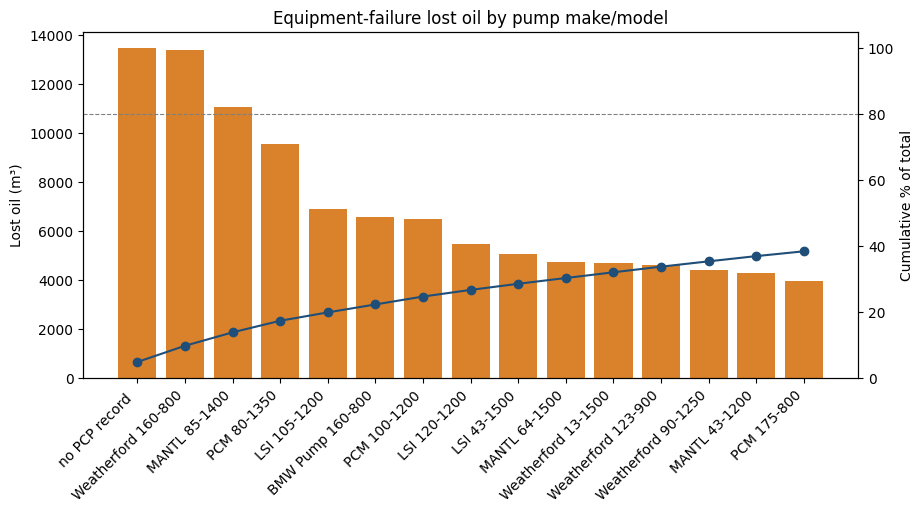

523 of 1,313 wells with equipment downtime (39.8%) account for 80% of equipment-failure lost oil


,hours_down,lost_oil_m3,wells,share,cumulative_share
uwi,,,,,
101062003420W300,"12,497.000","4,889.719",1,0.018,0.018
101083203420W300,"4,088.000","3,118.782",1,0.011,0.029
104143404125W300,"3,864.250","2,443.412",1,0.009,0.038
192153403420W300,"9,157.000","2,137.770",1,0.008,0.046
106012104225W300,"10,531.000","2,030.180",1,0.007,0.054
102042103701W400,"16,852.000","1,991.436",1,0.007,0.061
106151803728W300,"8,090.000","1,919.455",1,0.007,0.068
195090604325W300,"7,925.250","1,531.363",1,0.006,0.074
104123203601W400,"11,494.500","1,496.870",1,0.006,0.079


In [7]:
pareto_area = pareto(eq, "field_operating_area")
pareto_model = pareto(eq.assign(pump=eq["pcp_pump_make"].astype("string").fillna("no PCP record") + " "
                                 + eq["pcp_pump_model"].astype("string").fillna("")), "pump")
pareto_well = pareto(eq, "uwi")
for name, t in [("field_area", pareto_area), ("pump_model", pareto_model), ("well", pareto_well)]:
    save_table(t, f"3_1_pareto_{name}")
display(pareto_area.head(10))
display(pareto_model.head(10))
plot_pareto(pareto_area, "Equipment-failure lost oil by field operating area", "3_1_pareto_field_area")
plot_pareto(pareto_model, "Equipment-failure lost oil by pump make/model", "3_1_pareto_pump_model")

n80 = int((pareto_well["cumulative_share"] < 0.8).sum() + 1)
print(f"{n80:,} of {len(pareto_well):,} wells with equipment downtime "
      f"({n80 / len(pareto_well):.1%}) account for 80% of equipment-failure lost oil")
top_wells = pareto_well.head(20)
display(top_wells)

### Equipment-failure rate by pump model and field (normalised)
The Pareto charts above show totals, which favour common pump models and big fields. Here the totals are
divided by **well-years of operation**, so models and fields can be compared fairly (only groups with 20+ wells).

In [8]:
exposure = prod.assign(year_frac=1 / 365.25)
exposure["pump"] = (prod["pcp_pump_make"].astype("string").fillna("no PCP record") + " "
                    + prod["pcp_pump_model"].astype("string").fillna(""))
eq_starts = (prod["downtime_class"].isin(ANALYSIS_CLASSES)
             & ~prod.groupby("uwi")["downtime_class"].shift(1).isin(ANALYSIS_CLASSES))
exposure["eq_start"] = eq_starts
rates = {}
for by in ["pump", "field_operating_area"]:
    r = (exposure.groupby(by, observed=True)
                 .agg(wells=("uwi", "nunique"), well_years=("year_frac", "sum"),
                      outages=("eq_start", "sum"), lost_oil_m3=("lost_oil_m3", "sum")))
    r = r[r["wells"] >= 20]
    r["outages_per_well_year"] = r["outages"] / r["well_years"]
    r["lost_oil_m3_per_well_year"] = r["lost_oil_m3"] / r["well_years"]
    rates[by] = r.sort_values("outages_per_well_year", ascending=False)
    save_table(rates[by], f"3_1_rate_by_{by}")
    display(rates[by].head(10))

,wells,well_years,outages,lost_oil_m3,outages_per_well_year,lost_oil_m3_per_well_year
pump,,,,,,
LSI 105-1000,25,27.997,290,"7,075.212",10.358,252.711
LSI 20-1200,26,22.776,205,"2,000.724",9.001,87.843
Weatherford 90-1250,58,61.429,549,"7,200.392",8.937,117.215
LSI 105-1200,58,50.919,454,"9,094.692",8.916,178.613
Weatherford 75-1200,34,38.207,338,"3,307.501",8.847,86.569
PCM 27-1200,20,13.229,115,"5,109.286",8.693,386.210
Mantl 85-1400,28,18.694,159,"1,786.413",8.505,95.561
LSI 85-1250,51,48.290,407,"5,976.400",8.428,123.760
PCM 120-1200,30,34.809,286,"5,394.458",8.216,154.973


,wells,well_years,outages,lost_oil_m3,outages_per_well_year,lost_oil_m3_per_well_year
field_operating_area,,,,,,
Druid Main,162,588.386,4389,"76,737.278",7.459,130.420
Cosine,79,320.630,2178,"29,344.302",6.793,91.521
Winter,325,"1,079.841",6164,"215,204.614",5.708,199.293
Druid North East,45,206.116,1154,"26,992.918",5.599,130.960
Bodo East,91,453.624,2219,"47,236.652",4.892,104.132
Bellis,27,101.810,459,"6,226.372",4.508,61.157
Cactus Lake,640,"3,089.804",12761,"130,654.747",4.130,42.286
Bodo Main,22,105.580,325,"2,183.046",3.078,20.677
Court,186,992.635,2758,"35,893.244",2.778,36.160


### B. Explanatory model: which well conditions are associated with equipment-failure losses?

**Unit of analysis:** one oil-producing well on one day *t*, where the well ran all of day *t-1*
(`hours_down == 0`). This asks: *given the well's condition while it was running, how much equipment-failure
downtime and lost oil follow on day t?* Without the "ran yesterday" filter, the model would mostly learn that a well
already down yesterday is still down today.

**Targets (same day):** `hours_down` and `lost_oil_m3` for equipment-failure downtime (0 on normal days).
Days with downtime from other classes (economic, planned, external...) are set aside, not counted as 0.

**No same-day leakage:** same-day oil/water/gas, throughput, `hours_on_prod` and the downtime codes are **not**
features: they restate or label the target. Every sensor feature uses data up to day *t-1* only.

In [9]:
SENSORS = {  # feature prefix: cleaned column
    "eff": "pump_efficiency_pct", "rpm": "pcp_pump_rpm", "torque": "pcp_pump_rod_torque_ftlb",
    "current": "pcp_pump_electric_current_a", "tbg_p": "tubing_pressure_kpa",
    "csg_p": "casing_pressure_kpa", "wcut": "water_cut", "oil": "oil_produced_m3",
}
FACTOR_GROUPS = {
    "eff": "Pump efficiency", "rpm": "Pump speed (RPM)", "torque": "Rod torque",
    "current": "Motor current", "tbg_p": "Tubing pressure", "csg_p": "Casing pressure",
    "wcut": "Water cut", "oil": "Recent oil rate", "well_age": "Well age",
    "days_since_last_failure": "Failure history", "failures_prev_365": "Failure history",
    "days_since_last_job": "Service-job history", "jobs_prev_365": "Service-job history",
    "last_job": "Service-job history", "pcp_pump": "Pump type", "pump_displacement": "Pump type",
    "field_operating_area": "Location", "facility_name": "Location",
}

jobs = du.extract_summary_flags(du.clean_jobs(du.convert_types(du.load_jobs()), verbose=True), verbose=False)
failures = du.clean_failures(du.extract_failure_depth(du.convert_types(du.load_failures()), verbose=False),
                             verbose=False)
JOB_FLAGS = [c for c in jobs.columns if c.startswith("sum_")]


def _asof(left, right, right_date, cols, left_date="production_date"):
    """For each (uwi, day) take the latest right-hand event dated STRICTLY BEFORE the day."""
    l = left[["uwi", left_date]].reset_index()
    l[left_date] = l[left_date].astype("datetime64[ns]")
    r = right[["uwi", right_date] + cols].dropna(subset=[right_date]).sort_values(right_date)
    r[right_date] = r[right_date].astype("datetime64[ns]")
    m = pd.merge_asof(l.sort_values(left_date), r, left_on=left_date, right_on=right_date,
                      by="uwi", allow_exact_matches=False, direction="backward")
    return m.set_index("index").reindex(left.index)


def _count_prev(left, events, event_date, days=365):
    """Number of events per well in [t - days, t)."""
    ev = events[["uwi", event_date]].dropna().sort_values(["uwi", event_date]).copy()
    ev["cum"] = ev.groupby("uwi").cumcount() + 1
    now = _asof(left, ev, event_date, ["cum"])["cum"].fillna(0)
    shifted = left[["uwi"]].assign(_d=left["production_date"] - pd.Timedelta(days=days))
    before = _asof(shifted, ev, event_date, ["cum"], left_date="_d")["cum"].fillna(0)
    return (now - before).astype("float32")


def build_features(d, jobs, failures):
    """Past-only features for every row of ``d`` (sorted by uwi, production_date; one row per day)."""
    d = d.copy()
    liquid = d["oil_produced_m3"] + d["water_produced_m3"]
    d["water_cut"] = (d["water_produced_m3"] / liquid).where(liquid > 0)
    feats = pd.DataFrame(index=d.index)

    # Lag 1: only when the previous row is the previous calendar day.
    g = d.groupby("uwi", sort=True)
    consecutive = (d["production_date"] - g["production_date"].shift(1)) == pd.Timedelta(days=1)
    for name, col in SENSORS.items():
        feats[f"{name}_lag1"] = g[col].shift(1).where(consecutive)

    # Rolling windows over the previous 7 / 30 calendar days, excluding day t (closed="left").
    src = d[["uwi", "production_date"] + list(SENSORS.values())].set_index("production_date")
    for win in (7, 30):
        r = src.groupby("uwi", sort=True).rolling(f"{win}D", closed="left")
        mean = r.mean().reset_index(drop=True)
        for name, col in SENSORS.items():
            feats[f"{name}_mean{win}"] = mean[col].to_numpy()
        if win == 7:
            std = r.std().reset_index(drop=True)
            for name, col in SENSORS.items():
                feats[f"{name}_std7"] = std[col].to_numpy()
    for name in SENSORS:
        # Recent drift: last-7-day average minus last-30-day average (e.g. falling efficiency < 0).
        feats[f"{name}_drift7v30"] = feats[f"{name}_mean7"] - feats[f"{name}_mean30"]

    # Static / slowly changing context.
    feats["well_age_years"] = (d["production_date"] - d["on_production_date"]).dt.days / 365.25
    feats["pump_displacement"] = d["pcp_pump_displacement_m3d100rpm"]
    for col in ["pcp_pump_make", "pcp_pump_model", "field_operating_area", "facility_name"]:
        feats[col] = d[col]

    # Event history, strictly before day t.
    last_fail = _asof(d, failures, "failure_start_date", [])
    feats["days_since_last_failure"] = (d["production_date"] - last_fail["failure_start_date"]).dt.days
    feats["failures_prev_365"] = _count_prev(d, failures, "failure_start_date")
    last_job = _asof(d, jobs, "start_date", ["job_category"] + JOB_FLAGS)
    feats["days_since_last_job"] = (d["production_date"] - last_job["start_date"]).dt.days
    feats["jobs_prev_365"] = _count_prev(d, jobs, "start_date")
    feats["last_job_category"] = last_job["job_category"].astype("category")
    for c in JOB_FLAGS:
        feats[f"last_job_{c}"] = last_job[c].astype("float32")

    num = feats.select_dtypes("number").columns
    feats[num] = feats[num].astype("float32")
    return feats


features = build_features(prod, jobs, failures)
CAT_FEATURES = list(features.select_dtypes("category").columns)
print(f"{features.shape[1]} features built for {len(features):,} rows "
      f"({len(CAT_FEATURES)} categorical: {CAT_FEATURES})")

  start_date                       -> datetime (0 values could not be parsed)
  end_date                         -> datetime (0 values could not be parsed)
job_duration_days: 65 negative values -> NaN
field_est_total: 1 negative values -> NaN
  failure_start_date               -> datetime (0 values could not be parsed)
  failure_end_date                 -> datetime (0 values could not be parsed)


58 features built for 3,351,538 rows (5 categorical: ['pcp_pump_make', 'pcp_pump_model', 'field_operating_area', 'facility_name', 'last_job_category'])


**Leakage test.** For one well, add 10,000 to every raw sensor/volume value from day *t* onward and add a fake job
and failure on day *t*, then rebuild the features. The day-*t* feature row must not change.

In [10]:
test_well = prod["uwi"].value_counts().index[0]
w = prod[prod["uwi"] == test_well].copy()
t_day = w["production_date"].iloc[len(w) // 2]
changed = w.copy()
future = changed["production_date"] >= t_day
for col in list(SENSORS.values())[:-2] + ["oil_produced_m3", "water_produced_m3"]:
    changed.loc[future, col] = changed.loc[future, col] + 10_000
fake_job = jobs.iloc[[0]].assign(uwi=test_well, start_date=t_day)
fake_fail = failures.iloc[[0]].assign(uwi=test_well, failure_start_date=t_day)
orig_row = build_features(w, jobs, failures).loc[w["production_date"] == t_day]
new_row = build_features(changed, pd.concat([jobs, fake_job]), pd.concat([failures, fake_fail])).loc[
    changed["production_date"] == t_day]
pd.testing.assert_frame_equal(orig_row, new_row)
print(f"Leakage test passed: well {test_well}, day {t_day.date()} - features unchanged by day-t+ data.")

Leakage test passed: well 100013403620W402, day 2023-11-29 - features unchanged by day-t+ data.


In [11]:
prev_hours = prod.groupby("uwi")["hours_down"].shift(1)
prev_date = prod.groupby("uwi")["production_date"].shift(1)
ran_yesterday = (prev_hours == 0) & ((prod["production_date"] - prev_date) == pd.Timedelta(days=1))
in_scope_today = (prod["hours_down"] == 0) | prod["downtime_class"].isin(ANALYSIS_CLASSES)
rows = ran_yesterday & in_scope_today

model_df = features.loc[rows].copy()
model_df["production_date"] = prod.loc[rows, "production_date"]
model_df["uwi"] = prod.loc[rows, "uwi"]
model_df["y_hours"] = prod.loc[rows, "hours_down"].astype("float32")
model_df["y_lost"] = prod.loc[rows, "lost_oil_m3"].astype("float32")
print(f"Modelling rows (oil producer ran all of yesterday, today normal or equipment failure): {len(model_df):,}")
print(f"Share of rows with equipment-failure downtime today: {(model_df['y_hours'] > 0).mean():.2%}")
print(f"Rows with downtime but no lost-oil estimate (dropped for the lost-oil target only): "
      f"{model_df['y_lost'].isna().sum():,}")

dates = np.sort(model_df["production_date"].unique())
cutoff = pd.Timestamp(dates[int(len(dates) * 0.8)])
train = model_df[model_df["production_date"] < cutoff].sort_values("production_date")
test = model_df[model_df["production_date"] >= cutoff]
assert train["production_date"].max() < test["production_date"].min()
print(f"Train: {train['production_date'].min().date()} to {train['production_date'].max().date()} "
      f"({len(train):,} rows) | Test: {test['production_date'].min().date()} to "
      f"{test['production_date'].max().date()} ({len(test):,} rows)")
FEATURES = [c for c in features.columns]

Modelling rows (oil producer ran all of yesterday, today normal or equipment failure): 1,806,524
Share of rows with equipment-failure downtime today: 1.83%
Rows with downtime but no lost-oil estimate (dropped for the lost-oil target only): 3


Train: 2021-01-02 to 2025-08-27 (1,445,696 rows) | Test: 2025-08-28 to 2026-10-26 (360,828 rows)


**Tuning:** walk-forward validation (`TimeSeriesSplit`, 3 folds, rows in date order) on a random 25% of the
training **wells**, to keep the run time to a few minutes. Ten random parameter sets per target are scored by
validation RMSE. `lost_oil_m3` is heavily skewed, so its model is fitted on `log1p(lost_oil_m3)` and its predictions
are transformed back before scoring.

In [12]:
PARAM_SPACE = {
    "n_estimators": [150, 250, 400], "learning_rate": [0.03, 0.06, 0.1], "max_depth": [4, 6, 8],
    "min_child_weight": [5, 20, 50], "subsample": [0.7, 0.9], "colsample_bytree": [0.6, 0.8],
}
rng = np.random.default_rng(RANDOM_STATE)
tune_wells = rng.choice(train["uwi"].unique(), size=int(train["uwi"].nunique() * 0.25), replace=False)


def make_model(params):
    return xgb.XGBRegressor(tree_method="hist", enable_categorical=True, max_cat_to_onehot=1,
                            n_jobs=-1, random_state=RANDOM_STATE, **params)


def tune(target, log_target):
    data = train[train["uwi"].isin(tune_wells)].dropna(subset=[target])
    X, y = data[FEATURES], data[target]
    y_fit = np.log1p(y) if log_target else y
    results = []
    for params in ParameterSampler(PARAM_SPACE, n_iter=10, random_state=RANDOM_STATE):
        fold_rmse = []
        for fit_idx, val_idx in TimeSeriesSplit(n_splits=3).split(X):
            m = make_model(params).fit(X.iloc[fit_idx], y_fit.iloc[fit_idx])
            pred = m.predict(X.iloc[val_idx])
            pred = np.expm1(pred).clip(0) if log_target else pred.clip(0)
            fold_rmse.append(np.sqrt(mean_squared_error(y.iloc[val_idx], pred)))
        results.append({**params, "cv_rmse": np.mean(fold_rmse)})
    res = pd.DataFrame(results).sort_values("cv_rmse")
    best = {k: (int(v) if k in ("n_estimators", "max_depth", "min_child_weight") else float(v))
            for k, v in res.iloc[0].drop("cv_rmse").items()}
    print(f"{target}: best walk-forward RMSE {res['cv_rmse'].iloc[0]:.3f} with {best}")
    return best


TARGETS = {"y_hours": dict(log=False, label="hours_down"), "y_lost": dict(log=True, label="lost_oil_m3")}
best_params = {t: tune(t, cfg["log"]) for t, cfg in TARGETS.items()}

y_hours: best walk-forward RMSE 1.680 with {'subsample': 0.9, 'n_estimators': 250, 'min_child_weight': 20, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


y_lost: best walk-forward RMSE 0.430 with {'subsample': 0.7, 'n_estimators': 150, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


In [13]:
models, scores = {}, []
for target, cfg in TARGETS.items():
    tr = train.dropna(subset=[target])
    te = test.dropna(subset=[target])
    y_fit = np.log1p(tr[target]) if cfg["log"] else tr[target]
    models[target] = make_model(best_params[target]).fit(tr[FEATURES], y_fit)
    pred = models[target].predict(te[FEATURES])
    pred = np.expm1(pred).clip(0) if cfg["log"] else pred.clip(0)
    # Naive baseline: each well's average target in the training period (global mean for new wells).
    well_mean = tr.groupby("uwi")[target].mean()
    base = te["uwi"].map(well_mean).fillna(tr[target].mean()).to_numpy()
    any_down = (te["y_hours"] > 0).astype(int)
    for name, p in [("XGBoost", pred), ("Baseline: per-well training mean", base)]:
        scores.append({
            "target": cfg["label"], "model": name,
            "MAE": mean_absolute_error(te[target], p),
            "RMSE": np.sqrt(mean_squared_error(te[target], p)),
            "ROC-AUC (any downtime)": roc_auc_score(any_down, p),
            "PR-AUC (any downtime)": average_precision_score(any_down, p),
        })
    test.loc[te.index, f"pred_{target}"] = pred
scores = pd.DataFrame(scores).set_index(["target", "model"])
display(scores)
save_table(scores, "3_1_model_vs_baseline")
print(f"Positive rate in the test period: {(test['y_hours'] > 0).mean():.2%} "
      "(PR-AUC of a random guess equals this rate)")

MAE  RMSE  ROC-AUC (any downtime)  PR-AUC (any downtime)
target      model                                                                                      
hours_down  XGBoost                          0.378 1.672                   0.623                  0.032
            Baseline: per-well training mean 0.369 1.687                   0.579                  0.025
lost_oil_m3 XGBoost                          0.054 0.586                   0.588                  0.026
            Baseline: per-well training mean 0.070 0.588                   0.590                  0.026

Positive rate in the test period: 1.96% (PR-AUC of a random guess equals this rate)


**Reading the scores.** Equipment-failure downtime starts on only ~2% of running well-days, and the model is only
**modestly better than the naive baseline**: for `hours_down` the ROC-AUC rises from ~0.58 to ~0.62 and the PR-AUC
from ~0.025 to ~0.032 (random = ~0.02). For `lost_oil_m3` it is no better than the baseline. So, from the previous
days' readings alone, a failure on a *specific day* is hard to predict. The SHAP results below are therefore
**supporting evidence** about which conditions are associated with risk, not a precise risk model. The Pareto,
episode and cost analyses carry more weight in the conclusions.

### SHAP: which features drive the predictions (holdout period)

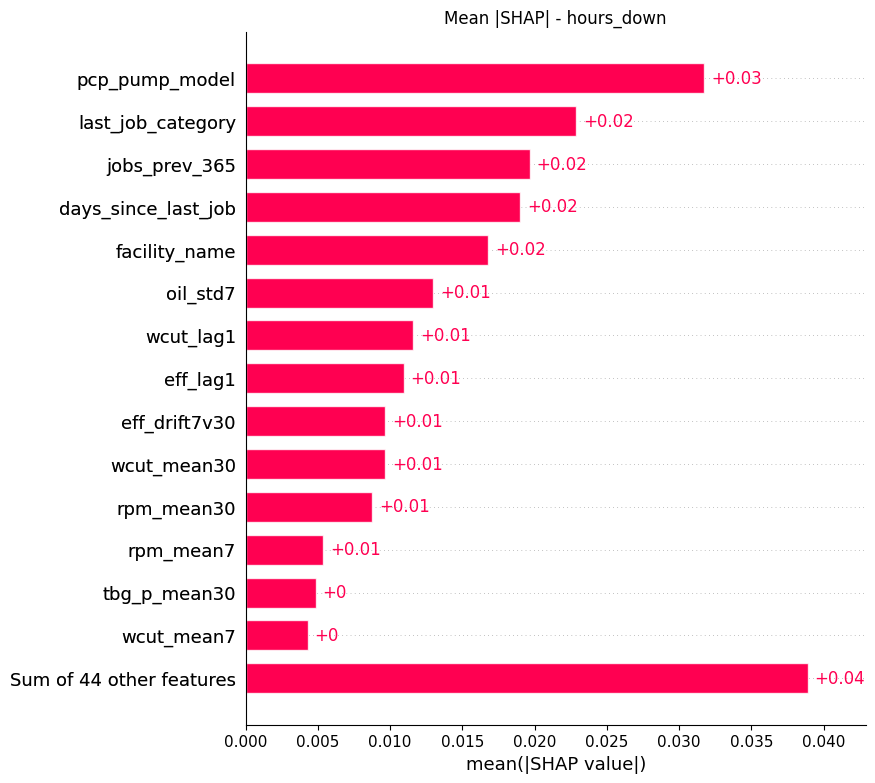

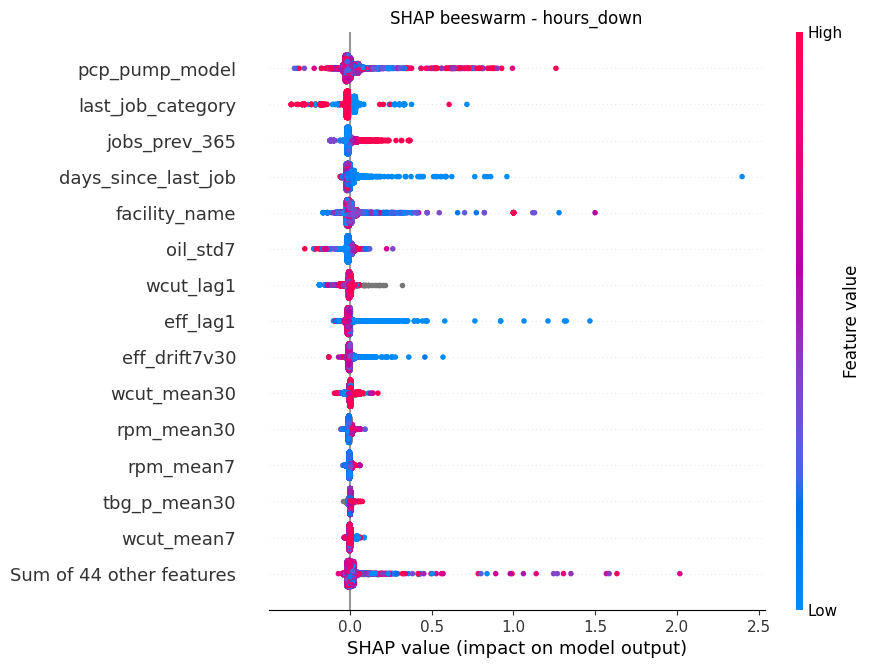

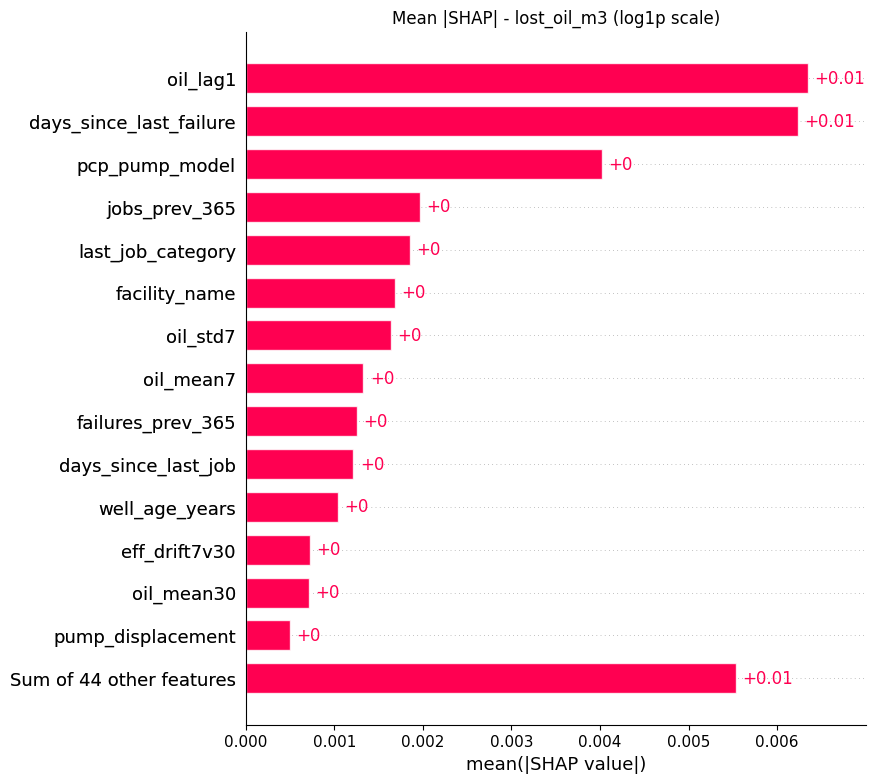

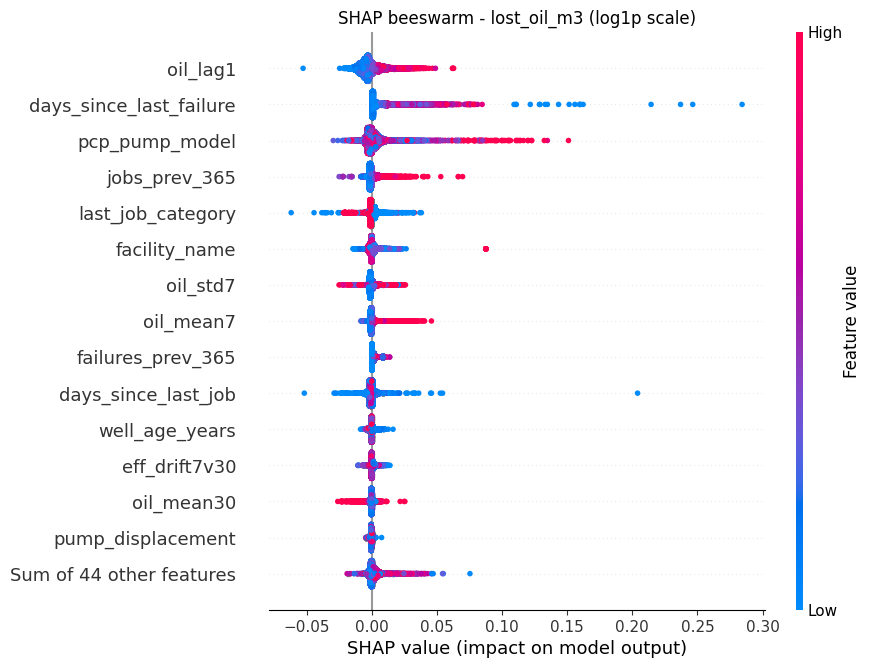

In [14]:
shap_sample = test.sample(n=min(20_000, len(test)), random_state=RANDOM_STATE)
explanations = {}
for target, cfg in TARGETS.items():
    booster = models[target].get_booster()
    dm = xgb.DMatrix(shap_sample[FEATURES], enable_categorical=True)
    contrib = booster.predict(dm, pred_contribs=True)
    shown = shap_sample[FEATURES].copy()
    for c in CAT_FEATURES:
        shown[c] = shown[c].cat.codes.replace(-1, np.nan)
    explanations[target] = shap.Explanation(values=contrib[:, :-1], base_values=contrib[:, -1],
                                            data=shown.to_numpy(dtype=float), feature_names=FEATURES)
    label = cfg["label"] + (" (log1p scale)" if cfg["log"] else "")
    shap.plots.bar(explanations[target], max_display=15, show=False)
    plt.title(f"Mean |SHAP| - {label}")
    save_fig(plt.gcf(), f"3_1_shap_bar_{cfg['label']}")
    plt.show()
    shap.plots.beeswarm(explanations[target], max_display=15, show=False)
    plt.title(f"SHAP beeswarm - {label}")
    save_fig(plt.gcf(), f"3_1_shap_beeswarm_{cfg['label']}")
    plt.show()

In [15]:
def factor_group(feature):
    for key, group in FACTOR_GROUPS.items():
        if feature.startswith(key):
            return group
    return feature


importance = []
for target, cfg in TARGETS.items():
    e = explanations[target]
    imp = pd.DataFrame({"feature": FEATURES, "mean_abs_shap": np.abs(e.values).mean(axis=0)})
    # Direction: rank correlation between the feature value and its SHAP value.
    imp["direction_corr"] = [
        pd.Series(e.data[:, i]).corr(pd.Series(e.values[:, i]), method="spearman")
        if FEATURES[i] not in CAT_FEATURES else np.nan for i in range(len(FEATURES))]
    imp["target"] = cfg["label"]
    imp["share_of_total_shap"] = imp["mean_abs_shap"] / imp["mean_abs_shap"].sum()
    imp["rank"] = imp["mean_abs_shap"].rank(ascending=False).astype(int)
    importance.append(imp)
importance = pd.concat(importance)
importance["factor"] = importance["feature"].map(factor_group)
save_table(importance.sort_values(["target", "rank"]).set_index(["target", "rank"]), "3_1_shap_feature_importance")
group_imp = (importance.groupby(["factor", "target"])["share_of_total_shap"].sum()
                       .unstack("target").sort_values("hours_down", ascending=False))
display(group_imp.style.format("{:.1%}") if hasattr(group_imp, "style") else group_imp)
save_table(group_imp, "3_1_shap_factor_groups")
display(importance[importance["rank"] <= 12].sort_values(["target", "rank"])
        [["target", "rank", "feature", "factor", "share_of_total_shap", "direction_corr"]])

C:\Users\Karanvir\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


C:\Users\Karanvir\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


target,hours_down,lost_oil_m3
factor,,
Service-job history,27.6%,14.0%
Pump type,15.6%,13.1%
Water cut,12.7%,1.6%
Pump efficiency,12.0%,4.3%
Recent oil rate,8.1%,28.4%
Location,7.8%,4.9%
Pump speed (RPM),6.9%,4.5%
Tubing pressure,4.3%,2.1%
Rod torque,1.5%,1.5%


,target,rank,feature,factor,share_of_total_shap,direction_corr
43,hours_down,1,pcp_pump_model,Pump type,0.140,NaN
50,hours_down,2,last_job_category,Service-job history,0.101,NaN
49,hours_down,3,jobs_prev_365,Service-job history,0.087,0.874
48,hours_down,4,days_since_last_job,Service-job history,0.084,-0.802
45,hours_down,5,facility_name,Location,0.074,NaN
23,hours_down,6,oil_std7,Recent oil rate,0.057,0.794
6,hours_down,7,wcut_lag1,Water cut,0.051,0.396
0,hours_down,8,eff_lag1,Pump efficiency,0.048,-0.617
32,hours_down,9,eff_drift7v30,Pump efficiency,0.043,-0.837
30,hours_down,10,wcut_mean30,Water cut,0.043,0.889


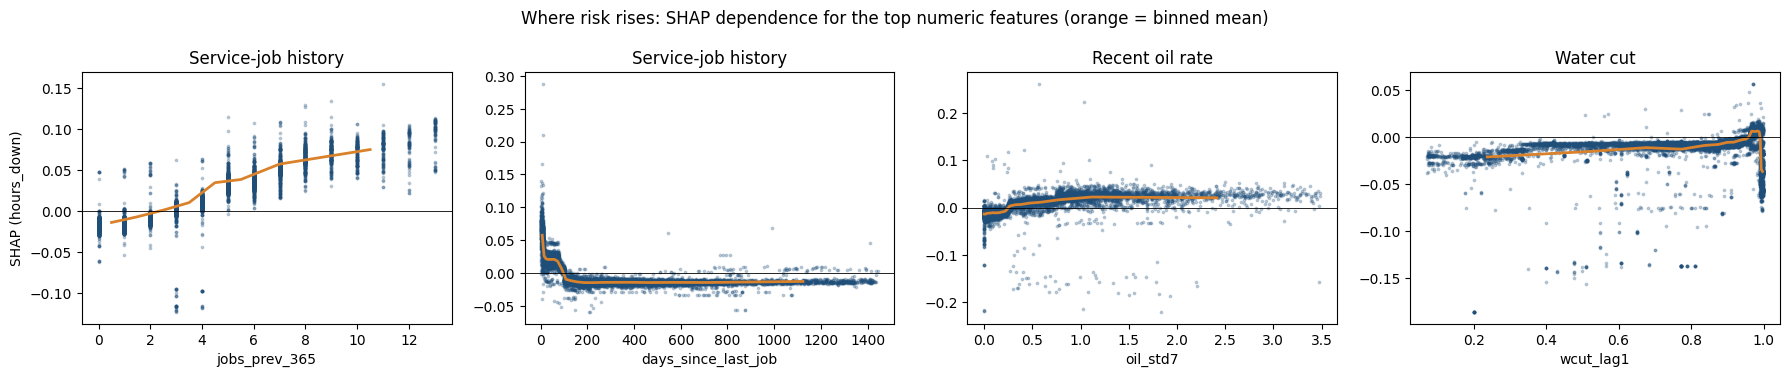

In [16]:
top_numeric = (importance[(importance["target"] == "hours_down") & ~importance["feature"].isin(CAT_FEATURES)]
               .sort_values("rank")["feature"].head(4).tolist())
fig, axes = plt.subplots(1, len(top_numeric), figsize=(4.5 * len(top_numeric), 3.8))
e = explanations["y_hours"]
for ax, feat in zip(axes, top_numeric):
    i = FEATURES.index(feat)
    x, s = e.data[:, i], e.values[:, i]
    ok = ~np.isnan(x)
    lo, hi = np.nanpercentile(x, [1, 99])
    keep = ok & (x >= lo) & (x <= hi)
    ax.scatter(x[keep], s[keep], s=3, alpha=0.25, color="#1f4e79")
    bins = pd.qcut(pd.Series(x[keep]), 20, duplicates="drop")
    trend = pd.Series(s[keep]).groupby(bins, observed=True).mean()
    ax.plot([b.mid for b in trend.index], trend.to_numpy(), color="#d9822b", lw=2)
    ax.axhline(0, color="black", lw=0.6)
    ax.set(xlabel=feat, ylabel="SHAP (hours_down)" if ax is axes[0] else "", title=factor_group(feat))
fig.suptitle("Where risk rises: SHAP dependence for the top numeric features (orange = binned mean)")
fig.tight_layout()
save_fig(fig, "3_1_shap_dependence_top")
plt.show()

### 3.1 summary: top factors

In [17]:
def top_feature_direction(group, target="hours_down"):
    sub = importance[(importance["target"] == target) & (importance["factor"] == group)].sort_values("rank")
    row = sub.iloc[0]
    if pd.isna(row["direction_corr"]):
        return row["feature"], "categorical (some categories higher risk)"
    return row["feature"], "higher value -> more downtime" if row["direction_corr"] > 0 else "lower value -> more downtime"


factor_rows = []
for group in group_imp.index[:8]:
    feat, direction = top_feature_direction(group)
    factor_rows.append({"factor": group, "evidence": "SHAP (model)",
                        "share of SHAP, hours_down": group_imp.loc[group, "hours_down"],
                        "share of SHAP, lost_oil_m3": group_imp.loc[group, "lost_oil_m3"],
                        "strongest feature": feat, "direction": direction})
for problem, r in pareto_problem.head(4).iterrows():
    factor_rows.append({"factor": f"Downtime code: {problem}", "evidence": "Pareto (descriptive)",
                        "share of equipment lost oil": r["share"], "direction": "-"})
factor_table = pd.DataFrame(factor_rows)
display(factor_table)
save_table(factor_table.set_index("factor"), "3_1_top_factor_table")

,factor,evidence,"share of SHAP, hours_down","share of SHAP, lost_oil_m3",strongest feature,direction,share of equipment lost oil
0,Service-job history,SHAP (model),0.276,0.140,last_job_category,categorical (some categories higher risk),NaN
1,Pump type,SHAP (model),0.156,0.131,pcp_pump_model,categorical (some categories higher risk),NaN
2,Water cut,SHAP (model),0.127,0.016,wcut_lag1,higher value -> more downtime,NaN
3,Pump efficiency,SHAP (model),0.120,0.043,eff_lag1,lower value -> more downtime,NaN
4,Recent oil rate,SHAP (model),0.081,0.284,oil_std7,higher value -> more downtime,NaN
5,Location,SHAP (model),0.078,0.049,facility_name,categorical (some categories higher risk),NaN
6,Pump speed (RPM),SHAP (model),0.069,0.045,rpm_mean30,higher value -> more downtime,NaN
7,Tubing pressure,SHAP (model),0.043,0.021,tbg_p_mean30,higher value -> more downtime,NaN
8,Downtime code: Rod string failure,Pareto (descriptive),NaN,NaN,NaN,-,0.443
9,Downtime code: Pump failure / problems,Pareto (descriptive),NaN,NaN,NaN,-,0.141


## 3.2 Cross-reference with failure type/detail (Goal step 2)

**Downtime episodes:** consecutive equipment-failure downtime days on one well form one episode.
Failures and repair jobs are linked to an episode when they are on the same well and dated within
`LINK_WINDOW_DAYS` of it (`[start - 3d, end + 3d]`). Each failure or job is linked to at most one episode, the one
whose start is closest.

In [18]:
eqd = prod[prod["downtime_class"].isin(ANALYSIS_CLASSES)].copy()
eqd["row_id"] = eqd.index
new_ep = (eqd["uwi"] != eqd["uwi"].shift()) | (eqd["production_date"] - eqd["production_date"].shift()
                                                 != pd.Timedelta(days=1))
eqd["episode_id"] = new_ep.cumsum()
dominant = (eqd.groupby(["episode_id", "problem"], observed=True)["hours_down"].sum()
               .reset_index().sort_values("hours_down").drop_duplicates("episode_id", keep="last")
               .set_index("episode_id")["problem"])
episodes = eqd.groupby("episode_id").agg(
    uwi=("uwi", "first"), start=("production_date", "min"), end=("production_date", "max"),
    days=("production_date", "size"), hours_down=("hours_down", "sum"),
    lost_oil_m3=("lost_oil_m3", lambda s: s.sum(min_count=1)), start_row=("row_id", "first"),
    field_operating_area=("field_operating_area", "first"))
episodes["problem"] = dominant.astype("string")
print(f"{len(episodes):,} equipment-failure episodes on {episodes['uwi'].nunique():,} wells")
display(episodes["days"].describe(percentiles=[0.5, 0.75, 0.9, 0.99]).to_frame("episode length (days)").T)
long_eps = episodes["days"] > 90
print(f"Episodes longer than 90 days: {long_eps.sum():,} ({long_eps.mean():.1%}) but "
      f"{episodes.loc[long_eps, 'lost_oil_m3'].sum() / episodes['lost_oil_m3'].sum():.1%} of lost oil. "
      "These look like failed wells left down (repair deferred), not a single repair.")

REPAIR_JOB_CATEGORIES = ["Rod Truck", "Workover", "Coil Job", "Surface Failure"]


def link_events(events, date_col, window=LINK_WINDOW_DAYS):
    ev = events.reset_index(names="event_id")
    m = ev.merge(episodes.reset_index()[["episode_id", "uwi", "start", "end"]], on="uwi")
    in_window = ((m[date_col] >= m["start"] - pd.Timedelta(days=window))
                 & (m[date_col] <= m["end"] + pd.Timedelta(days=window)))
    m = m[in_window].assign(gap=lambda x: (x[date_col] - x["start"]).abs())
    return m.sort_values("gap").drop_duplicates("event_id")


fail_links = link_events(failures, "failure_start_date")
repair_jobs = jobs[jobs["job_category"].isin(REPAIR_JOB_CATEGORIES)]
job_links = link_events(repair_jobs, "start_date")

first_fail = fail_links.sort_values("gap").drop_duplicates("episode_id").set_index("episode_id")
for col in ["failure_type_std", "cause_std", "failure_detail"]:
    episodes[col] = first_fail[col].astype("string").reindex(episodes.index)
episodes["failure_depth_m"] = first_fail["failure_depth_m"].astype("float").reindex(episodes.index)
episodes["repair_cost_cad"] = job_links.groupby("episode_id")["field_est_total"].sum().reindex(episodes.index)
episodes["repair_jobs"] = job_links.groupby("episode_id").size().reindex(episodes.index).fillna(0)

covered = episodes["start"] >= failures["failure_start_date"].min()
link_rates = pd.Series({
    "episodes": len(episodes),
    "episodes in failure-record period (from 2021-12-14)": int(covered.sum()),
    "...with a linked failure record": f"{episodes.loc[covered, 'failure_type_std'].notna().mean():.1%}",
    "episodes with a linked repair job": f"{(episodes['repair_jobs'] > 0).mean():.1%}",
    "...share of lost oil in episodes with a failure record": f"{episodes.loc[covered & episodes['failure_type_std'].notna(), 'lost_oil_m3'].sum() / episodes.loc[covered, 'lost_oil_m3'].sum():.1%}",
    "...share of lost oil in episodes with a repair job": f"{episodes.loc[episodes['repair_jobs'] > 0, 'lost_oil_m3'].sum() / episodes['lost_oil_m3'].sum():.1%}",
    "failure records linked to an episode": f"{fail_links['event_id'].nunique() / len(failures):.1%}",
    "repair jobs linked to an episode": f"{job_links['event_id'].nunique() / len(repair_jobs):.1%}",
}, name="value")
display(link_rates.to_frame())
save_table(link_rates.to_frame(), "3_2_link_rates")

34,181 equipment-failure episodes on 1,313 wells


,count,mean,std,min,50%,75%,90%,99%,max
episode length (days),"34,181.000",4.543,26.918,1.000,1.000,3.000,7.000,39.200,"1,065.000"


Episodes longer than 90 days: 175 (0.5%) but 14.7% of lost oil. These look like failed wells left down (repair deferred), not a single repair.


,value
episodes,34181
episodes in failure-record period (from 2021-12-14),30566
...with a linked failure record,7.8%
episodes with a linked repair job,29.7%
...share of lost oil in episodes with a failure record,15.8%
...share of lost oil in episodes with a repair job,72.2%
failure records linked to an episode,90.5%
repair jobs linked to an episode,85.8%


failure_type_std,no failure record,Rods,Pump,Tubing,Casing,Sand
problem,,,,,,
Rod string failure,"95,058.000","23,713.000",826.000,610.000,18.000,0.000
Pump failure / problems,"35,328.000",980.000,"2,020.000",718.000,0.000,6.000
Tubing failure,"26,390.000","1,306.000","1,707.000","3,007.000",0.000,0.000
Well torqued,"17,103.000",365.000,"1,128.000",167.000,0.000,0.000
Facility upset / emergency shutdown,"11,798.000",222.000,17.000,3.000,0.000,0.000
Engine / motor down,"11,696.000",42.000,1.000,0.000,0.000,0.000
Other downhole problem,"8,644.000",750.000,750.000,175.000,0.000,0.000
Flowline / pipeline problem,"7,979.000",30.000,0.000,0.000,0.000,0.000


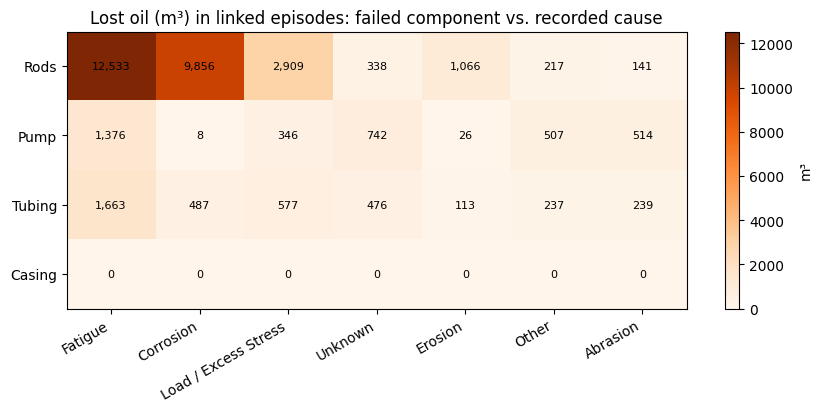

,episodes,lost_oil_m3,median_depth_m
failure_detail,,,
Rods Routine - Broken Corod body,649,"8,626.740",392.000
Rods Routine - Broken Sucker Rod Body,507,"7,633.873",883.000
Burnt/Low Inflow,114,"2,349.450",NaN
Parted,71,"2,286.744",119.500
Rod - Broken Corod Body,139,"2,068.145",410.000
Rods Routine - Polished Rod,114,"1,682.616",NaN
Rods Routine - Bottom Pin,104,"1,674.868",NaN
Rods Routine - Upset,116,"1,574.838",933.000
Rods Routine - Box,86,"1,489.503",NaN


In [19]:
xt = pd.crosstab(episodes["problem"], episodes["failure_type_std"].fillna("no failure record"),
                 values=episodes["lost_oil_m3"], aggfunc="sum").fillna(0)
xt = xt.loc[xt.sum(axis=1).sort_values(ascending=False).index[:8]]
xt = xt[xt.sum().sort_values(ascending=False).index[:6]]
display(xt.round(0))
save_table(xt, "3_2_problem_vs_failure_type_lost_oil")

cause_xt = pd.crosstab(episodes["failure_type_std"], episodes["cause_std"], values=episodes["lost_oil_m3"],
                       aggfunc="sum").fillna(0)
cause_xt = cause_xt.loc[cause_xt.sum(axis=1).sort_values(ascending=False).index[:4],
                        cause_xt.sum().sort_values(ascending=False).index[:7]]
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(cause_xt.to_numpy(), cmap="Oranges", aspect="auto")
ax.set_xticks(range(cause_xt.shape[1]), cause_xt.columns, rotation=30, ha="right")
ax.set_yticks(range(cause_xt.shape[0]), cause_xt.index)
for i in range(cause_xt.shape[0]):
    for j in range(cause_xt.shape[1]):
        ax.text(j, i, f"{cause_xt.iloc[i, j]:,.0f}", ha="center", va="center", fontsize=8)
ax.set_title("Lost oil (m³) in linked episodes: failed component vs. recorded cause")
fig.colorbar(im, ax=ax, label="m³")
save_fig(fig, "3_2_failure_type_vs_cause_heatmap")
plt.show()
save_table(cause_xt, "3_2_failure_type_vs_cause_lost_oil")

detail = (episodes.dropna(subset=["failure_detail"]).groupby("failure_detail")
                  .agg(episodes=("uwi", "size"), lost_oil_m3=("lost_oil_m3", "sum"),
                       median_depth_m=("failure_depth_m", "median"))
                  .sort_values("lost_oil_m3", ascending=False).head(12))
display(detail)
save_table(detail, "3_2_failure_detail_top")

**Top factors vs. failure modes.** For each top numeric model factor, linked episodes are split into quartiles
of that factor's value **on the day the episode started** (a past-only feature), and we show which failed
components and recorded causes dominate each quartile.

In [20]:
ep_feats = features.loc[episodes["start_row"].to_numpy()].set_index(episodes.index)
top_factor_feats = [f for f in (importance[(importance["target"] == "hours_down")
                                           & ~importance["feature"].isin(CAT_FEATURES)]
                                .sort_values("rank")["feature"]) if ep_feats[f].notna().mean() > 0.2][:3]
linked = episodes["failure_type_std"].notna()
factor_modes = []
for feat in top_factor_feats:
    q = pd.qcut(ep_feats.loc[linked, feat], 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"], duplicates="drop")
    tab = pd.crosstab(q, episodes.loc[linked, "failure_type_std"], normalize="index").mul(100)
    cause = pd.crosstab(q, episodes.loc[linked, "cause_std"], normalize="index").mul(100)
    top_causes = cause[cause.sum().sort_values(ascending=False).index[:3]]
    out = pd.concat({"component %": tab[tab.sum().sort_values(ascending=False).index[:3]],
                     "cause %": top_causes}, axis=1)
    out["episodes"] = q.value_counts().reindex(out.index)
    out.index = pd.MultiIndex.from_product([[feat], out.index])
    factor_modes.append(out)
factor_modes = pd.concat(factor_modes)
display(factor_modes.round(1))
save_table(factor_modes, "3_2_top_factor_quartiles_vs_failure_modes")

component %               cause %                                episodes
                                     Rods   Pump Tubing Fatigue Corrosion Load / Excess Stress         
jobs_prev_365       Q1 (low)       63.200 25.700 11.100  37.900    29.800                6.300      728
                    Q2             82.500  9.100  8.300  45.900    31.100               11.700      593
                    Q3             84.400  8.900  6.700  48.200    29.300               12.000      571
                    Q4 (high)      89.900  5.400  4.600  52.700    26.600               12.400      483
days_since_last_job Q1 (low)       82.000 10.800  6.900  50.500    25.000               12.100      595
                    Q2             83.800  8.500  7.700  48.400    30.500               10.500      600
                    Q3             84.700  9.800  5.500  42.500    34.500               10.800      582
                    Q4 (high)      63.900 24.300 11.700  40.800    27.100                7.700      588
oil_std7            Q1 (low)       72.200 17.300 10.400  40.500    29.700                8.500      594
                    Q2             79.600 13.000  7.300  43.900    29.000               12.100      593
                    Q3             84.500  9.300  6.100  49.100    32.800                8.900      593
                    Q4 (high)      77.900 14.000  8.100  48.600    25.900               11.800      594

## 3.3 Cost of each problem (Goal step 3)

Lost revenue = `lost_oil_m3` x 6.2898 bbl/m³ x heavy-oil price (CAD/bbl, `OIL_PRICE_CAD_PER_BBL`).
Repair cost = `field_est_total` of the repair jobs linked to the episode. **Caveats:** `lost_oil_m3` is the
operator's estimate, and some of it may be *deferred* (recovered later) rather than permanently lost. Episodes
without a linked job have no repair cost, so the repair totals are a lower bound.

,episodes,hours_down,lost_oil_m3,lost_revenue_cad,repair_cost_cad,total_cost_cad,lost_revenue_to_repair_ratio,total_cost_cad_per_year,cost_per_episode_cad
problem,,,,,,,,,
Rod string failure,"7,973","1,199,961","120,225","56,714,151","71,801,549","128,515,700",0.8,"22,099,981","16,119"
Pump failure / problems,"1,668","644,024","39,052","18,422,361","45,828,347","64,250,708",0.4,"11,048,762","38,520"
Tubing failure,877,"440,132","32,410","15,289,057","28,239,700","43,528,756",0.5,"7,485,348","49,634"
Well torqued,981,"196,246","18,764","8,851,566","9,488,470","18,340,036",0.9,"3,153,813","18,695"
Other downhole problem,463,"128,086","10,318","4,867,350","13,315,112","18,182,461",0.4,"3,126,716","39,271"
Facility upset / emergency shutdown,"12,040","68,619","12,041","5,680,070","1,485,537","7,165,607",3.8,"1,232,221",595
Engine / motor down,"4,437","106,199","11,739","5,537,492","873,519","6,411,011",6.3,"1,102,459","1,445"
Wellhead drive / stuffing box,"1,518","80,232","7,783","3,671,684","619,670","4,291,353",5.9,"737,955","2,827"
Flowline / pipeline problem,"1,670","76,107","8,009","3,777,945","237,388","4,015,334",15.9,"690,490","2,404"


,episodes,hours_down,lost_oil_m3,lost_revenue_cad,repair_cost_cad,total_cost_cad,lost_revenue_to_repair_ratio,total_cost_cad_per_year,cost_per_episode_cad
failure_type_std,,,,,,,,,
no failure record,31806,"2,716,457.250","233,215.540","110,015,932.782","130,671,367.970","240,687,300.752",0.842,"41,389,376.930","7,567.355"
Rods,1865,"199,621.500","27,682.463","13,058,786.697","21,702,614.780","34,761,401.477",0.602,"5,977,684.505","18,638.821"
Pump,318,"81,311.250","6,486.580","3,059,946.855","12,411,703.360","15,471,650.215",0.247,"2,660,555.669","48,652.988"
Tubing,190,"48,221.750","4,684.195","2,209,698.585","7,931,101.530","10,140,800.115",0.279,"1,743,845.217","53,372.632"
Sand,1,98.000,6.400,"3,018.956","29,612.450","32,631.406",0.102,"5,611.404","32,631.406"
Casing,1,186.000,17.593,"8,299.023","24,296.450","32,595.473",0.342,"5,605.224","32,595.473"


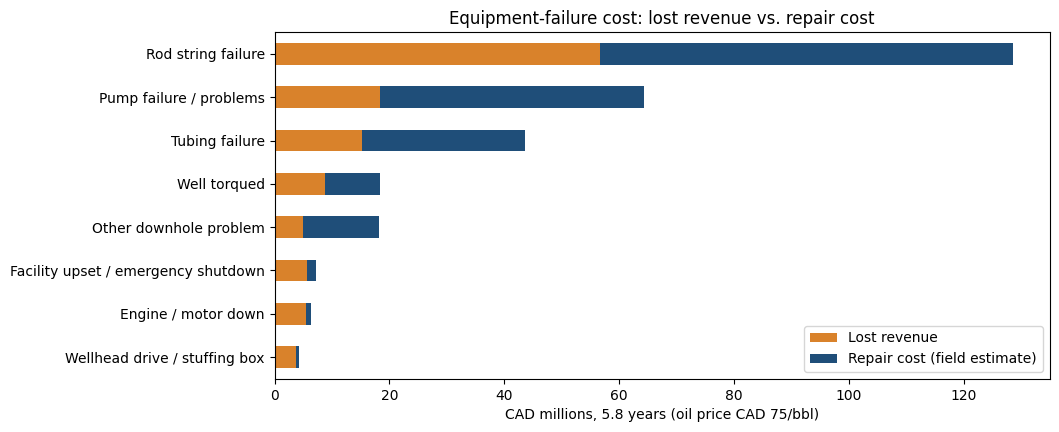

,price CAD/bbl,lost revenue CAD/yr,repair cost CAD/yr,total CAD/yr
low,55,"16,186,473","29,710,215","45,896,689"
base,75,"22,072,464","29,710,215","51,782,679"
high,95,"27,958,454","29,710,215","57,668,669"


In [21]:
price = OIL_PRICE_CAD_PER_BBL["base"]
episodes["lost_revenue_cad"] = episodes["lost_oil_m3"] * BBL_PER_M3 * price
years_of_data = (prod["production_date"].max() - prod["production_date"].min()).days / 365.25


def cost_table(by):
    t = episodes.groupby(by, observed=True).agg(
        episodes=("uwi", "size"), hours_down=("hours_down", "sum"), lost_oil_m3=("lost_oil_m3", "sum"),
        lost_revenue_cad=("lost_revenue_cad", "sum"), repair_cost_cad=("repair_cost_cad", "sum"))
    t["total_cost_cad"] = t["lost_revenue_cad"] + t["repair_cost_cad"]
    t["lost_revenue_to_repair_ratio"] = t["lost_revenue_cad"] / t["repair_cost_cad"].replace(0, np.nan)
    t["total_cost_cad_per_year"] = t["total_cost_cad"] / years_of_data
    t["cost_per_episode_cad"] = t["total_cost_cad"] / t["episodes"]
    return t.sort_values("total_cost_cad", ascending=False)


cost_by_problem = cost_table("problem")
cost_by_component = cost_table(episodes["failure_type_std"].fillna("no failure record"))
display(cost_by_problem.style.format("{:,.0f}", subset=[c for c in cost_by_problem.columns
                                                        if c != "lost_revenue_to_repair_ratio"])
        .format("{:.1f}", subset=["lost_revenue_to_repair_ratio"]))
display(cost_by_component)
save_table(cost_by_problem, "3_3_cost_by_problem")
save_table(cost_by_component, "3_3_cost_by_failed_component")

fig, ax = plt.subplots(figsize=(10, 4.5))
top = cost_by_problem.head(8)[["lost_revenue_cad", "repair_cost_cad"]].div(1e6)
top.plot.barh(stacked=True, ax=ax, color=["#d9822b", "#1f4e79"])
ax.invert_yaxis()
ax.set(xlabel=f"CAD millions, {years_of_data:.1f} years (oil price CAD {price:.0f}/bbl)", ylabel="",
       title="Equipment-failure cost: lost revenue vs. repair cost")
ax.legend(["Lost revenue", "Repair cost (field estimate)"])
save_fig(fig, "3_3_cost_by_problem")
plt.show()

sens = pd.DataFrame({
    case: {"price CAD/bbl": p,
           "lost revenue CAD/yr": episodes["lost_oil_m3"].sum() * BBL_PER_M3 * p / years_of_data,
           "repair cost CAD/yr": episodes["repair_cost_cad"].sum() / years_of_data}
    for case, p in OIL_PRICE_CAD_PER_BBL.items()}).T
sens["total CAD/yr"] = sens["lost revenue CAD/yr"] + sens["repair cost CAD/yr"]
display(sens.style.format("{:,.0f}"))
save_table(sens, "3_3_price_sensitivity")

## 3.4 Evidence for the plan and estimated profit increase (Goal step 4)

Two interventions, each tied to a top factor and sized from the data:

1. **Risk-based early warning (model).** Each day, flag the wells with the highest predicted equipment-failure
   downtime and send an operator to check them (pump speed, torque, rod string) before the failure.
   *Back-tested on the untouched holdout period.*
2. **Repeat-failure well programme.** Wells with 2+ failures in the previous 365 days get a root-cause review and a
   proactive rod-string/pump job, instead of waiting for the next break.

The **effect size** (how much downtime is avoided) is not known from this data, since nothing like this was done
before. So savings are shown for 10% / 25% / 40% of the *addressable* cost, alongside the intervention's own cost.

In [22]:
# --- 1. Early-warning back-test on the holdout period ------------------------------------------
ALERT_TOP_SHARE = 0.02  # flag the top 2% riskiest running wells each day
test_rows = test.copy()
test_rows["risk_rank"] = test_rows.groupby("production_date")["pred_y_hours"].rank(ascending=False, pct=True)
test_rows["alert"] = test_rows["risk_rank"] <= ALERT_TOP_SHARE
alerts = test_rows.loc[test_rows["alert"], ["uwi", "production_date"]]

test_eps = episodes[episodes["start"] >= test["production_date"].min()]
m = test_eps.reset_index()[["episode_id", "uwi", "start", "lost_oil_m3", "repair_cost_cad"]].merge(alerts, on="uwi")
lead = (m["start"] - m["production_date"]).dt.days
flagged_eps = m.loc[(lead >= 0) & (lead <= ALERT_LEAD_DAYS), "episode_id"].unique()
a = alerts.merge(test_eps[["uwi", "start"]], on="uwi", how="left")
a_lead = (a["start"] - a["production_date"]).dt.days
useful_alert = a.assign(ok=(a_lead >= 0) & (a_lead <= ALERT_LEAD_DAYS)).groupby(
    ["uwi", "production_date"])["ok"].any()
test_days = test["production_date"].nunique()
backtest = pd.Series({
    "holdout days": test_days,
    "alerts per day (avg)": len(alerts) / test_days,
    "equipment episodes in holdout": len(test_eps),
    f"episodes with an alert in the {ALERT_LEAD_DAYS} days before (recall)": len(flagged_eps) / len(test_eps),
    "share of holdout lost oil in flagged episodes": test_eps.loc[flagged_eps, "lost_oil_m3"].sum()
                                                       / test_eps["lost_oil_m3"].sum(),
    f"alerts followed by an episode within {ALERT_LEAD_DAYS} days (precision)": useful_alert.mean(),
    "base rate: running well-days followed by an episode within 7 days": np.nan,
}, name="value")
# Base rate for comparison: chance that a random running well-day is followed by an episode in 7 days.
r = test_rows[["uwi", "production_date"]].sample(50_000, random_state=RANDOM_STATE).merge(
    test_eps[["uwi", "start"]], on="uwi", how="left")
r_lead = (r["start"] - r["production_date"]).dt.days
backtest.iloc[-1] = r.assign(ok=(r_lead >= 0) & (r_lead <= ALERT_LEAD_DAYS)).groupby(
    ["uwi", "production_date"])["ok"].any().mean()
display(backtest.to_frame())
save_table(backtest.to_frame(), "3_4_alert_backtest")

# --- 2. Repeat-failure wells -------------------------------------------------------------------
ep_feats_hist = ep_feats["failures_prev_365"]
repeat = ep_feats_hist >= 2
fail_period = episodes["start"] >= failures["failure_start_date"].min() + pd.Timedelta(days=365)
repeat_share = (episodes.loc[fail_period & repeat, "lost_revenue_cad"].sum()
                + episodes.loc[fail_period & repeat, "repair_cost_cad"].sum()) / (
                episodes.loc[fail_period, "lost_revenue_cad"].sum()
                + episodes.loc[fail_period, "repair_cost_cad"].sum())
running = model_df["production_date"] >= failures["failure_start_date"].min() + pd.Timedelta(days=365)
rate_by_hist = (model_df.loc[running].assign(
    history=pd.cut(model_df.loc[running, "failures_prev_365"], [-1, 0, 1, 2, 100],
                   labels=["0", "1", "2", "3+"]))
    .groupby("history", observed=True)["y_hours"].agg(lambda s: (s > 0).mean() * 365))
display(rate_by_hist.to_frame("equipment-downtime onsets per well-year").T)
repeat_wells_per_year = (model_df.loc[running & (model_df["failures_prev_365"] >= 2)]
                         .groupby(model_df["production_date"].dt.year)["uwi"].nunique().mean())
print(f"Episodes on wells with 2+ failures in the prior year carry {repeat_share:.1%} of equipment-failure cost "
      f"(since Dec 2022); about {repeat_wells_per_year:.0f} wells qualify each year.")
save_table(rate_by_hist.to_frame("onsets_per_well_year"), "3_4_onset_rate_by_failure_history")

,value
holdout days,425.000
alerts per day (avg),16.449
equipment episodes in holdout,"7,321.000"
episodes with an alert in the 7 days before (recall),0.086
share of holdout lost oil in flagged episodes,0.140
alerts followed by an episode within 7 days (precision),0.254
base rate: running well-days followed by an episode within 7 days,0.130


history,0,1,2,3+
equipment-downtime onsets per well-year,6.933,7.639,8.214,10.437


Episodes on wells with 2+ failures in the prior year carry 15.7% of equipment-failure cost (since Dec 2022); about 391 wells qualify each year.


scenario,conservative,base,optimistic
intervention,,,
Early warning (model alerts),"-8,563,272","-7,899,102","-7,234,931"
Repeat-failure well programme,"-298,893","921,712","2,142,318"


Assumptions: oil price CAD 75/bbl (base); inspection CAD 1,500 per alert; proactive job = median Rod Truck field estimate (CAD 2,846) once per repeat-failure well per year. The two programmes overlap, so do not add them together.
Early warning break-even (conservative, 10% reduction): a check must cost less than CAD 74 per alert (6,004 alerts/yr)
Early warning break-even (base, 25% reduction): a check must cost less than CAD 184 per alert (6,004 alerts/yr)
Early warning break-even (optimistic, 40% reduction): a check must cost less than CAD 295 per alert (6,004 alerts/yr)


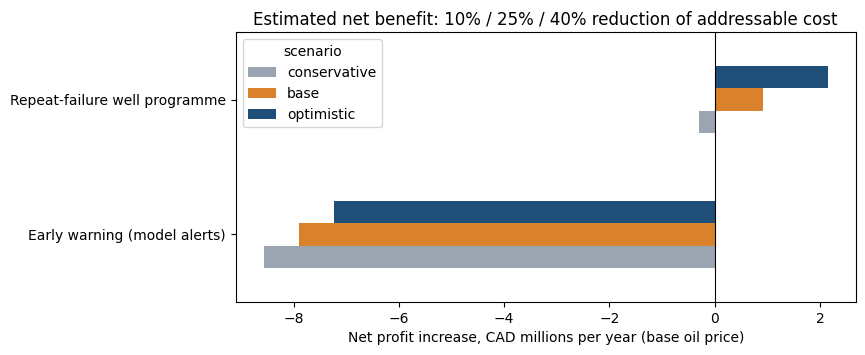

In [23]:
annual_cost = {case: (episodes["lost_oil_m3"].sum() * BBL_PER_M3 * p
                      + episodes["repair_cost_cad"].sum()) / years_of_data
               for case, p in OIL_PRICE_CAD_PER_BBL.items()}
rod_truck_cost = jobs.loc[jobs["job_category"] == "Rod Truck", "field_est_total"].median()
interventions = {
    "Early warning (model alerts)": dict(
        addressable_share=backtest[f"episodes with an alert in the {ALERT_LEAD_DAYS} days before (recall)"],
        annual_cost=backtest["alerts per day (avg)"] * 365 * INSPECTION_COST_CAD),
    "Repeat-failure well programme": dict(
        addressable_share=repeat_share,
        annual_cost=repeat_wells_per_year * rod_truck_cost),
}
rows_out = []
for name, iv in interventions.items():
    for case in OIL_PRICE_CAD_PER_BBL:
        for scenario, reduction in {"conservative": 0.10, "base": 0.25, "optimistic": 0.40}.items():
            avoided = annual_cost[case] * iv["addressable_share"] * reduction
            rows_out.append({"intervention": name, "oil price case": case, "scenario": scenario,
                             "reduction of addressable cost": reduction,
                             "addressable cost CAD/yr": annual_cost[case] * iv["addressable_share"],
                             "avoided cost CAD/yr": avoided, "intervention cost CAD/yr": iv["annual_cost"],
                             "net profit increase CAD/yr": avoided - iv["annual_cost"]})
scenarios = pd.DataFrame(rows_out)
save_table(scenarios.set_index(["intervention", "oil price case", "scenario"]), "3_4_profit_scenarios")
pivot = scenarios[scenarios["oil price case"] == "base"].pivot(
    index="intervention", columns="scenario", values="net profit increase CAD/yr")[
    ["conservative", "base", "optimistic"]]
display(pivot.style.format("{:,.0f}"))
print(f"Assumptions: oil price CAD {OIL_PRICE_CAD_PER_BBL['base']:.0f}/bbl (base); inspection CAD "
      f"{INSPECTION_COST_CAD:,} per alert; proactive job = median Rod Truck field estimate (CAD {rod_truck_cost:,.0f}) "
      "once per repeat-failure well per year. The two programmes overlap, so do not add them together.")
alerts_per_year = backtest["alerts per day (avg)"] * 365
for scenario, reduction in {"conservative": 0.10, "base": 0.25, "optimistic": 0.40}.items():
    avoided = annual_cost["base"] * interventions["Early warning (model alerts)"]["addressable_share"] * reduction
    print(f"Early warning break-even ({scenario}, {reduction:.0%} reduction): a check must cost less than "
          f"CAD {avoided / alerts_per_year:,.0f} per alert ({alerts_per_year:,.0f} alerts/yr)")

fig, ax = plt.subplots(figsize=(8, 3.5))
pivot.div(1e6).plot.barh(ax=ax, color=["#9aa5b1", "#d9822b", "#1f4e79"])
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Net profit increase, CAD millions per year (base oil price)", ylabel="",
       title="Estimated net benefit: 10% / 25% / 40% reduction of addressable cost")
save_fig(fig, "3_4_profit_scenarios")
plt.show()

## Findings (numbers from the run above; oil price is a placeholder to confirm)

**Where the losses are (3.0, 3.1 A)**
- Uneconomic long-term shut-ins are ~86% of downtime *hours* but only ~29% of lost oil. **Equipment failures are
  ~9% of hours but ~45% of lost oil**, and they are the controllable part.
- Within equipment failures, **rod-string failures are ~44% of lost oil**. Rods, pumps and tubing together make up
  ~70%. About 40% of the affected wells account for 80% of the lost oil.
- Normalised per well-year, some pump models and fields fail far more often than others (see the
  `3_1_rate_by_*` tables). That points to candidates for an equipment-standards review.

**Which conditions are associated with risk (3.1 B)**
- The model only modestly beats a per-well baseline, so treat SHAP as supporting evidence. The strongest associations
  are **service-job history** (more jobs in the past year and a recent job mean higher risk: wells that keep needing
  service keep failing), **pump type**, **water cut** (higher means more risk) and **pump efficiency** (lower, or
  drifting down over 7 vs. 30 days, means more risk).

**Failure modes behind the losses (3.2)**
- Linked failure records are dominated by **rods**, with **fatigue and corrosion** as the recorded causes, and broken
  corod / sucker-rod bodies as the most costly failure details. Wells with a heavy job history fail on rods more
  often (rods are ~90% of failures in the top job-history quartile vs. ~63% in the lowest).
- Only ~8% of equipment episodes link to a failure record (but ~90% of failure records link to an episode), so the
  failure file covers the larger repairs, not every stoppage.

**Cost (3.3)**
- Equipment failures cost roughly **CAD 46-58M per year** (lost revenue at CAD 55-95/bbl, plus ~CAD 30M/yr of
  repair field estimates). Rod-string failures alone are ~CAD 22M/yr.
- For most problems the repair bill is larger than the lost revenue, so **preventing a failure saves more than
  repairing it faster**.

**Plan and profit (3.4)**
- **Repeat-failure well programme:** wells with more failures in the past year start equipment downtime more often
  (about 6.9 per well-year with no prior failure vs. 10.4 with 3+). Targeting the ~390 wells a year with 2+ failures
  addresses ~16% of equipment-failure cost. The estimated net gain is **about CAD -0.3M to +2.1M per year
  (base ~CAD +0.9M)** for a 10-40% reduction.
- **Model-based early warning:** alerts are ~2x more likely than a random running well-day to be followed by an
  episode within 7 days (precision ~25% vs. a ~13% base rate). But they catch only ~9% of episodes, so a
  **dedicated** check per alert does not pay. It only makes sense where the check fits into existing operator rounds
  below the break-even cost printed above.
- **Lowest-risk next step:** start with the repeat-failure programme on the top-Pareto wells and pump models. Log
  every check and outcome, and use that log to measure the real effect size, which this data cannot provide.

## 3.5 Limitations

- **Sensor coverage:** after cleaning, pump efficiency is present on ~44%, rod torque on ~34% and motor current on
  ~24% of oil-producer rows. Many wells have no PCP telemetry, which limits the model.
- **Lost oil is an estimate:** `lost_oil_m3` is recorded by operators, and some of it may be *deferred* (recovered
  later) rather than lost. 24,735 downtime days have no estimate.
- **Weak day-level predictability:** the explanatory model is only modestly better than a per-well baseline.
  SHAP shows association, not causation.
- **Linking:** only ~8% of equipment episodes match a failure record, and ~30% match a repair job. Repair costs are
  therefore a lower bound, and the failure-mode mix describes the larger repairs.
- **Code classification:** the 149 downtime code pairs (two coding systems) were mapped to classes by keyword rules
  (`DOWNTIME_RULES`, saved in `outputs/downtime_code_mapping.csv`). Borderline cases, e.g. *Service Rig on Hole* or
  *UNECO - Tubing Failure*, are judgement calls for the team to confirm.
- **Outlier rules:** 99.9th-percentile caps and range rules (documented in `data_utils.py`) remove a small number
  of values. Different thresholds would change little but should be confirmed.
- **Profit estimate:** oil price, inspection cost and the reduction rates are assumptions, so the results are shown
  as ranges. Long episodes (>90 days, 0.5% of episodes but ~15% of lost oil) look like repairs deferred for
  economic reasons and may not be fully addressable.
- **Failure records start in Dec 2021**, so failure-history features are incomplete in 2021-2022.

**With more time:** model weekly risk per well instead of single days; use the full PCP telemetry (Canary
Historian) at higher frequency; run a pilot to measure the real effect of proactive rod replacement; break repair
cost into rig time, parts and labour.